In [6]:
'''## Lab - EDA Bivariate Analysis: Diving into Amazon UK Product Insights Part II

**Objective**: Delve into the dynamics of product pricing on Amazon UK to uncover insights that can inform business strategies and decision-making.

**Dataset**: This lab utilizes the [Amazon UK product dataset](https://www.kaggle.com/datasets/asaniczka/uk-optimal-product-price-prediction/)
which provides information on product categories, brands, prices, ratings, and more from from Amazon UK. You'll need to download it to start working with it.

---

### Part 1: Analyzing Best-Seller Trends Across Product Categories

**Objective**: Understand the relationship between product categories and their best-seller status.

1. **Crosstab Analysis**:
    - Create a crosstab between the product `category` and the `isBestSeller` status.
    
    - Are there categories where being a best-seller is more prevalent? 
    	
    	*Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.*


2. **Statistical Tests**:
    - Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
    - Compute Cramér's V to understand the strength of association between best-seller status and category.

3. **Visualizations**:
	- Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

---

### Part 2: Exploring Product Prices and Ratings Across Categories and Brands

**Objective**: Investigate how different product categories influence product prices.

0. **Preliminary Step: Remove outliers in product prices.**

	For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.
	
	*Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.*

1. **Violin Plots**:
    - Use a violin plot to visualize the distribution of `price` across different product `categories`. Filter out the top 20 categories based on count for better visualization.
    - Which product category tends to have the highest median price? Don't filter here by top categories.

2. **Bar Charts**:
    - Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
    - Which product category commands the highest average price? Don't filter here by top categories.

3. **Box Plots**:
    - Visualize the distribution of product `ratings` based on their `category` using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
    - Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

---

### Part 3: Investigating the Interplay Between Product Prices and Ratings

**Objective**: Analyze how product ratings (`stars`) correlate with product prices.

1. **Correlation Coefficients**:
    - Calculate the correlation coefficient between `price` and `stars`.
    - Is there a significant correlation between product price and its rating?
	
2. **Visualizations**:
    - Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
    - Use a correlation heatmap to visualize correlations between all numerical variables.
    - Examine if product prices typically follow a normal distribution using a QQ plot. 

---

**Submission**: Submit a Jupyter Notebook which contains code and a business-centric report summarizing your findings. 

**Bonus**: 

- Do the same analysis without taking out the outliers. What are your insights?
'''


"## Lab - EDA Bivariate Analysis: Diving into Amazon UK Product Insights Part II\n\n**Objective**: Delve into the dynamics of product pricing on Amazon UK to uncover insights that can inform business strategies and decision-making.\n\n**Dataset**: This lab utilizes the [Amazon UK product dataset](https://www.kaggle.com/datasets/asaniczka/uk-optimal-product-price-prediction/)\nwhich provides information on product categories, brands, prices, ratings, and more from from Amazon UK. You'll need to download it to start working with it.\n\n---\n\n### Part 1: Analyzing Best-Seller Trends Across Product Categories\n\n**Objective**: Understand the relationship between product categories and their best-seller status.\n\n1. **Crosstab Analysis**:\n    - Create a crosstab between the product `category` and the `isBestSeller` status.\n\n    - Are there categories where being a best-seller is more prevalent? \n\n    \t*Hint: one option is to calculate the proportion of best-sellers for each category

In [7]:

import pandas as pd


In [8]:
df=pd.read_csv("C:/Users/juana/OneDrive/Escritorio/ironhack/lab-eda-bivariate/archive (3)/amz_uk_price_prediction_dataset.csv")

In [9]:
df.head()


,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [10]:
df.dtypes

uid                    int64
asin                  object
title                 object
stars                float64
reviews                int64
price                float64
isBestSeller            bool
boughtInLastMonth      int64
category              object
dtype: object

In [11]:
df.nunique()

uid                  2443651
asin                 2222742
title                2077591
stars                     42
reviews                19446
price                  82916
isBestSeller               2
boughtInLastMonth         25
category                 296
dtype: int64

In [12]:
df.__len__

<bound method DataFrame.__len__ of              uid        asin  \
0              1  B09B96TG33   
1              2  B01HTH3C8S   
2              3  B09B8YWXDF   
3              4  B09B8T5VGV   
4              5  B09WX6QD65   
...          ...         ...   
2443646  2828589  B0CHSD7P2Q   
2443647  2828590  B0B7B8FNBQ   
2443648  2828591  B0BD5FL5FB   
2443649  2828592  B008OYLL4I   
2443650  2828593  B08P3W9B3T   

                                                     title  stars  reviews  \
0        Echo Dot (5th generation, 2022 release) | Big ...    4.7    15308   
1        Anker Soundcore mini, Super-Portable Bluetooth...    4.7    98099   
2        Echo Dot (5th generation, 2022 release) | Big ...    4.7    15308   
3        Echo Dot with clock (5th generation, 2022 rele...    4.7     7205   
4        Introducing Echo Pop | Full sound compact Wi-F...    4.6     1881   
...                                                    ...    ...      ...   
2443646  Motorbike Armour, Motorbi

In [13]:
'''1. **Crosstab Analysis**:
    - Create a crosstab between the product `category` and the `isBestSeller` status.
    
    - Are there categories where being a best-seller is more prevalent? 
    	
    	*Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.*
'''

'1. **Crosstab Analysis**:\n    - Create a crosstab between the product `category` and the `isBestSeller` status.\n\n    - Are there categories where being a best-seller is more prevalent? \n\n    \t*Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.*\n'

In [14]:
crosstab=pd.crosstab(df['category'],df['isBestSeller'])
crosstab.head()

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3


In [15]:
#prevalency
#Proportion of true
crosstab['best_s_ratio']=crosstab[True]/(crosstab[True]+crosstab[False])
#de mayor a menor
crosstab_sorted=crosstab.sort_values(by='best_s_ratio',ascending=False)

crosstab_sorted.head(5)

isBestSeller,False,True,best_s_ratio
category,,,
Grocery,9008,556,0.058135
Smart Home Security & Lighting,98,6,0.057692
Health & Personal Care,9017,552,0.057686
Mobile Phone Accessories,248,11,0.042471
Power & Hand Tools,8353,306,0.035339


In [16]:
'''2. **Statistical Tests**:
    - Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
    - Compute Cramér's V to understand the strength of association between best-seller status and category.
'''

"2. **Statistical Tests**:\n    - Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.\n    - Compute Cramér's V to understand the strength of association between best-seller status and category.\n"

In [17]:
## - Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
from scipy.stats import chi2_contingency

crosstab=pd.crosstab(df['category'],df['isBestSeller'])

chi2,p,dof,expected = chi2_contingency(crosstab)
print("Chi2:",chi2)
print("Grados de libertad: ",dof)
print("Valor p:",p)
#hay relacion completamente entre cateogria y si es best seller

Chi2: 36540.20270061387
Grados de libertad:  295
Valor p: 0.0


In [18]:
#como si hay relacion, veo que tan fuerte es la relación
import numpy as np

# Reutilizamos chi2 y crosstab de antes
n = crosstab.sum().sum()  # total de observaciones
min_dim = min(crosstab.shape) - 1  # el número más pequeño entre filas y columnas, menos 1

# Fórmula de Cramér's V
cramers_v = np.sqrt(chi2 / (n * min_dim))

print("Cramér's V:", cramers_v)
#~0.1	Relación débil

Cramér's V: 0.1222829439760564


In [19]:
'''3. **Visualizations**:
	- Visualize the relationship between product categories and the best-seller status using a stacked bar chart.
'''

'3. **Visualizations**:\n\t- Visualize the relationship between product categories and the best-seller status using a stacked bar chart.\n'

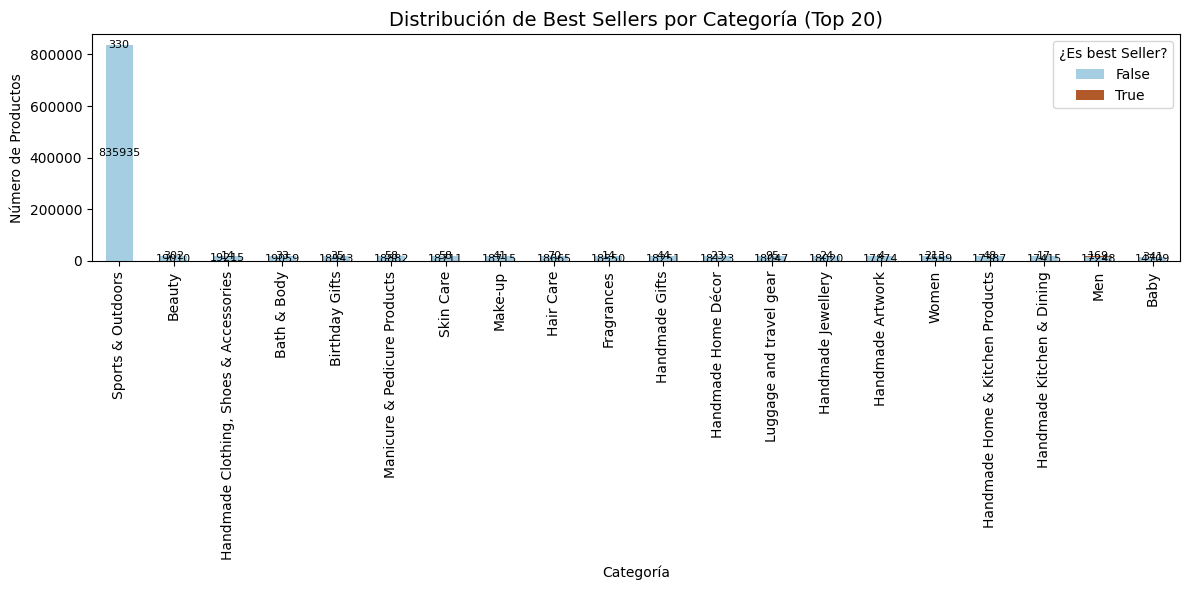

In [20]:
import matplotlib.pyplot as plt

# Usamos la crosstab que ya habías creado
crosstab_plot = pd.crosstab(df['category'], df['isBestSeller'])

# Para que se vean mejor, seleccionamos las 20 categorías con más productos
top_20_cats = df['category'].value_counts().head(20).index
crosstab_top = crosstab_plot.loc[top_20_cats]

# Creamos el gráfico
ax=crosstab_top.plot(kind='bar', stacked=True, figsize=(12,6), colormap='Paired')
# Añadir valores encima de cada parte de la barra
for bars in ax.containers:
    ax.bar_label(bars, label_type='center', fontsize=8)
# Títulos y etiquetas
plt.title('Distribución de Best Sellers por Categoría (Top 20)', fontsize=14)
plt.xlabel('Categoría')
plt.ylabel('Número de Productos')
plt.xticks(rotation=90)
plt.legend(title='¿Es best Seller?')
plt.tight_layout()
plt.show()


In [21]:
df['category'].value_counts()

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Motorbike Chassis                            107
Alexa Built-In Devices                       107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64

In [22]:
#2 precios y ratings

Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1

# Definimos umbrales
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Nuevo DataFrame sin outliers
df_no_outliers = df[(df['price'] >= lower_bound) & (df['price'] <= upper_bound)]


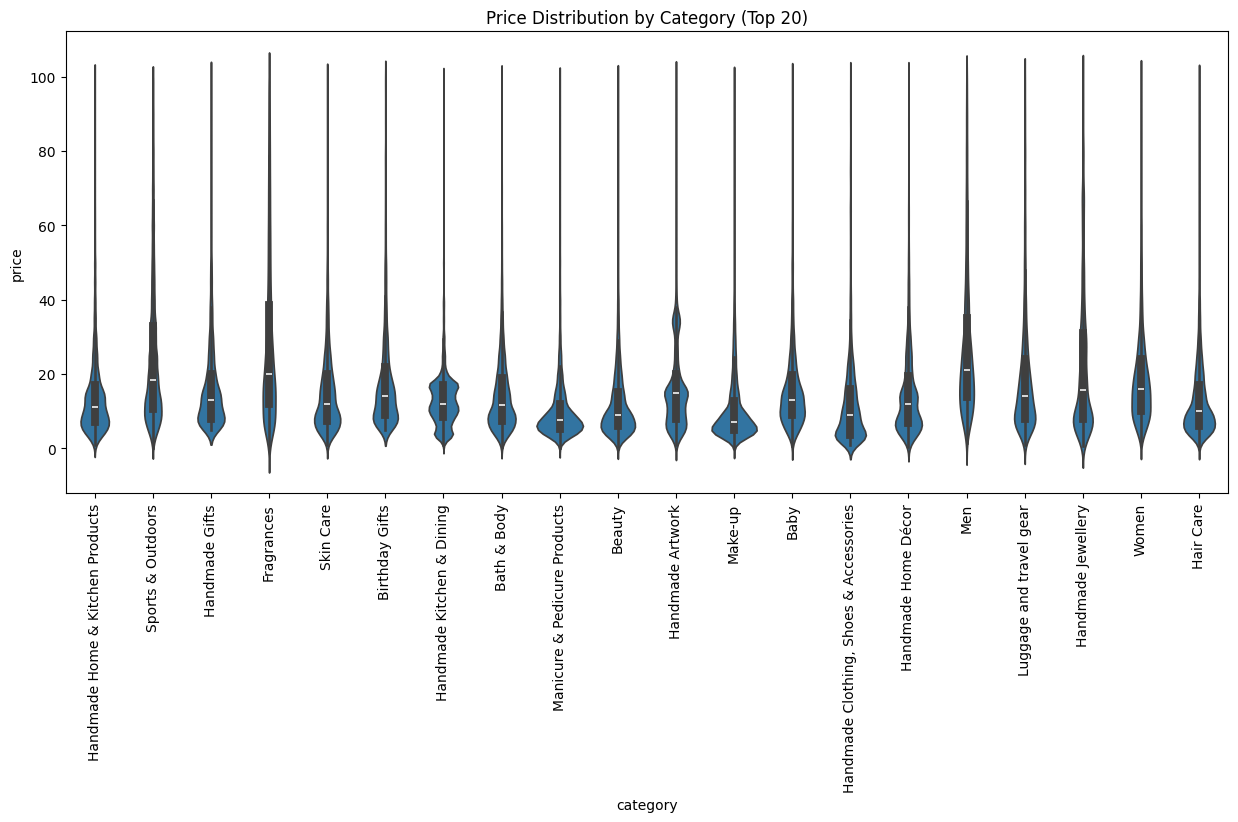

In [24]:

import seaborn as sns
#violin plot

top_20_cats = df_no_outliers['category'].value_counts().head(20).index
filtered_df = df_no_outliers[df_no_outliers['category'].isin(top_20_cats)]

plt.figure(figsize=(15,6))
sns.violinplot(data=filtered_df, x='category', y='price')
plt.xticks(rotation=90)
plt.title('Price Distribution by Category (Top 20)')
plt.show()


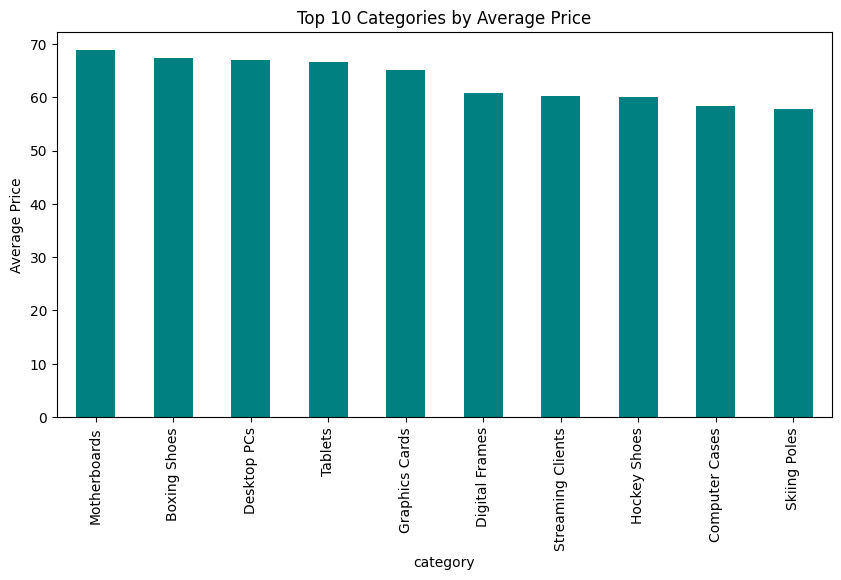

In [25]:
#barchart

avg_price = df_no_outliers.groupby('category')['price'].mean()
top10_avg_price = avg_price.sort_values(ascending=False).head(10)

top10_avg_price.plot(kind='bar', figsize=(10,5), color='teal')
plt.ylabel('Average Price')
plt.title('Top 10 Categories by Average Price')
plt.show()


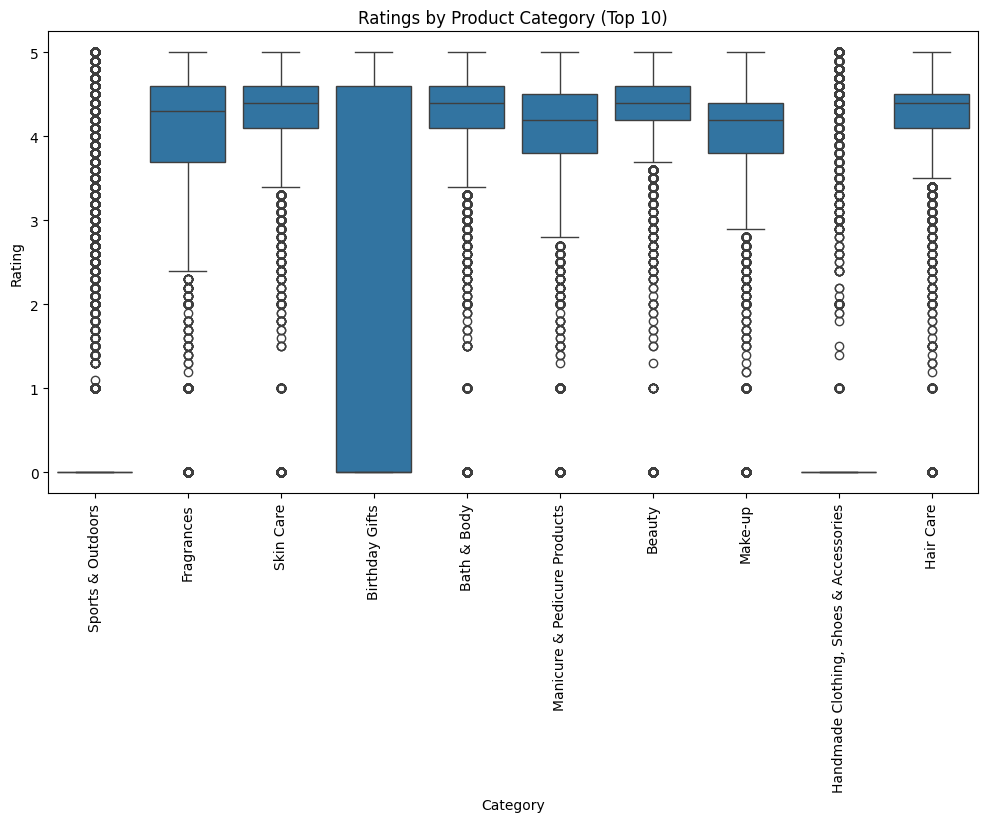

In [28]:
#boxplot 


import matplotlib.pyplot as plt

top10_rating_cats = df['category'].value_counts().head(10).index
rating_df = df[df['category'].isin(top10_rating_cats)]

# Asegúrate de que estás usando el nombre correcto de la columna (e.g., 'stars')
plt.figure(figsize=(12, 6))
sns.boxplot(data=rating_df, x='category', y='stars')  # usa 'stars' si no existe 'rating'
plt.xticks(rotation=90)
plt.title('Ratings by Product Category (Top 10)')
plt.ylabel('Rating')
plt.xlabel('Category')
plt.show()



In [29]:
correlation = df[['price', 'stars']].corr()
print("Correlation matrix:")
print(correlation)


Correlation matrix:
          price     stars
price  1.000000 -0.124907
stars -0.124907  1.000000


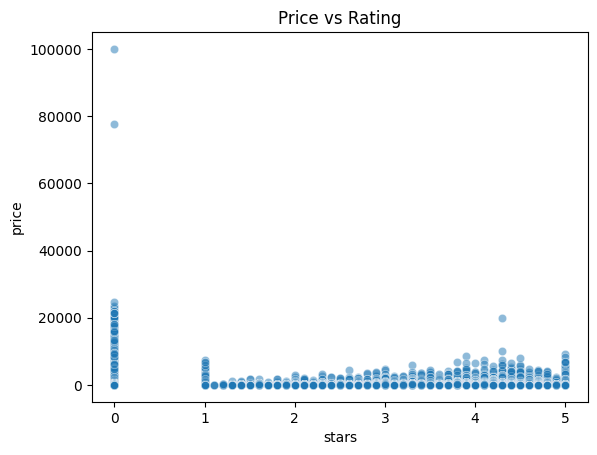

In [31]:
#sactter
sns.scatterplot(data=df, x='stars', y='price', alpha=0.5)
plt.title('Price vs Rating')
plt.show()


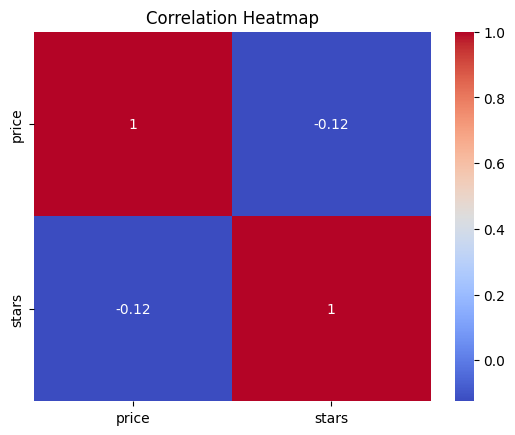

In [33]:
sns.heatmap(df[['price', 'stars']].corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()


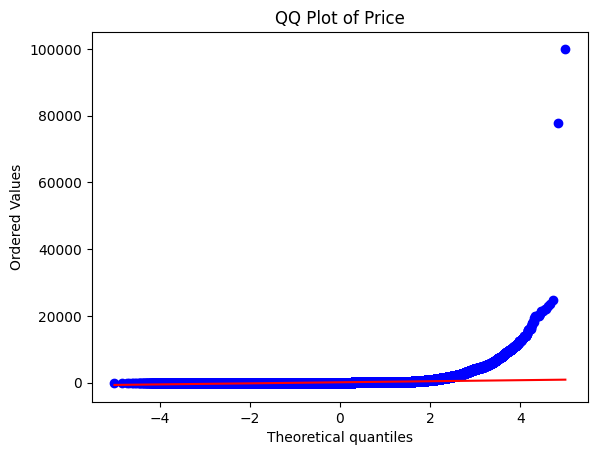

In [34]:
import scipy.stats as stats
import matplotlib.pyplot as plt

stats.probplot(df['price'], dist="norm", plot=plt)
plt.title("QQ Plot of Price")
plt.show()
